# 01 — Lojistik Regresyon ile Yangın Noktası Sınıflandırması

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Lojistik regresyon, adındaki "regresyon" sözcüğüne karşın bir **sınıflandırma**
yöntemidir. Özelliklerin doğrusal bir bileşimini lojistik (sigmoid) fonksiyondan geçirerek
bir noktanın yangın noktası olma olasılığını üretir; olasılık 0,5'i aşarsa nokta "Yangın"
olarak etiketlenir. Hızlıdır, karar sınırı yorumlanabilir ve katsayılarının işareti
özelliğin etki yönünü doğrudan gösterir. Yangın duyarlılığı alanyazınında en sık kullanılan
istatistiksel yöntemlerden biridir. Katsayıların karşılaştırılabilmesi ve optimizasyonun
dengeli ilerlemesi için özellikler ölçeklenir.

## 1. Veri Hazırlığı

Ölçekleme **yalnızca eğitim kümesine** oturtulur, teste dönüştürülerek uygulanır.
Ölçekleyiciyi bütün veriye oturtmak, test kümesinin ortalama ve varyans bilgisinin
eğitime sızmasına (data leakage) yol açar ve sonuçları iyimser biçimde saptırır.

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Model Eğitimi ve Test Performansı

`max_iter=2000` yalnızca yakınsama uyarısını önlemek içindir; modelin matematiğini
değiştirmez. `class_weight='balanced'` iki sınıfın ağırlığını sıklıklarıyla ters orantılı
yapar. Bu veri setinde sınıflar zaten neredeyse dengelidir (yaklaşık yarı yarıya); ayar,
bütün sınıflandırıcılarda aynı yöntembilimin izlenmesi için korunmuştur.

In [2]:
clf = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
olasilik = clf.predict_proba(X_te_s)[:, list(clf.classes_).index(o.POZITIF)]
auc = o.reg_metrikleri(yr_te, olasilik)["AUC"]
print(f"{'ROC-AUC':>14}: {auc:.4f}  (yangın olasılığının sıralama başarısı)")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.7348
   BalancedAcc: 0.7351
      F1_macro: 0.7348
   F1_weighted: 0.7348
       ROC-AUC: 0.8291  (yangın olasılığının sıralama başarısı)

              precision    recall  f1-score   support

  Yangın Yok      0.750     0.720     0.734       653
      Yangın      0.721     0.750     0.735       629

    accuracy                          0.735      1282
   macro avg      0.735     0.735     0.735      1282
weighted avg      0.735     0.735     0.735      1282



### 2.1 Taban Çizgileriyle Karşılaştırma

Bir sınıflandırma sonucunun anlamlı olup olmadığı iki ölçüte göre okunur: hiçbir şey
bilmeyen **çoğunluk sınıfı** tahmini ve eğitim kümesinden öğrenilmiş **tek bir eşik
sorusu** ("yükseklik şu değerin altındaysa yangın") ile yapılan tahmin. Asıl geçilmesi
gereken çizgi ikincisidir.

In [3]:
print("Taban çizgileri")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f} ise Yangın, değilse Yangın Yok")

Taban çizgileri
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.7348 |   0.5094 |    0.6934 | +0.0413
     BalancedAcc |  0.7351 |   0.5000 |    0.6982 | +0.0369
        F1_macro |  0.7348 |   0.3375 |    0.6748 | +0.0600
     F1_weighted |  0.7348 |   0.3438 |    0.6733 | +0.0614
Tek kural: Yükseklik ≤ 1258.0 ise Yangın, değilse Yangın Yok


In [4]:
o.karmasiklik_grafigi(yc_te, yp, "Lojistik Regresyon", "lojistik")

Lojistik Regresyon — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   470    183
      Yangın |   157    472


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\lojistik_siniflandirma.png'

## 3. Algoritmaya Özgü Analiz: Katsayıların Yorumu

Özellikler standartlaştırıldığı için katsayılar doğrudan karşılaştırılabilir: bir
katsayı, ilgili özelliğin bir standart sapmalık artışının "Yangın" sınıfının
log-olasılığını (log-odds) ne kadar değiştirdiğini gösterir. Pozitif katsayı yangın
olasılığını artırır, negatif katsayı azaltır. Arazi örtüsü göstergelerinin katsayıları
**orman alanına göre** okunur.

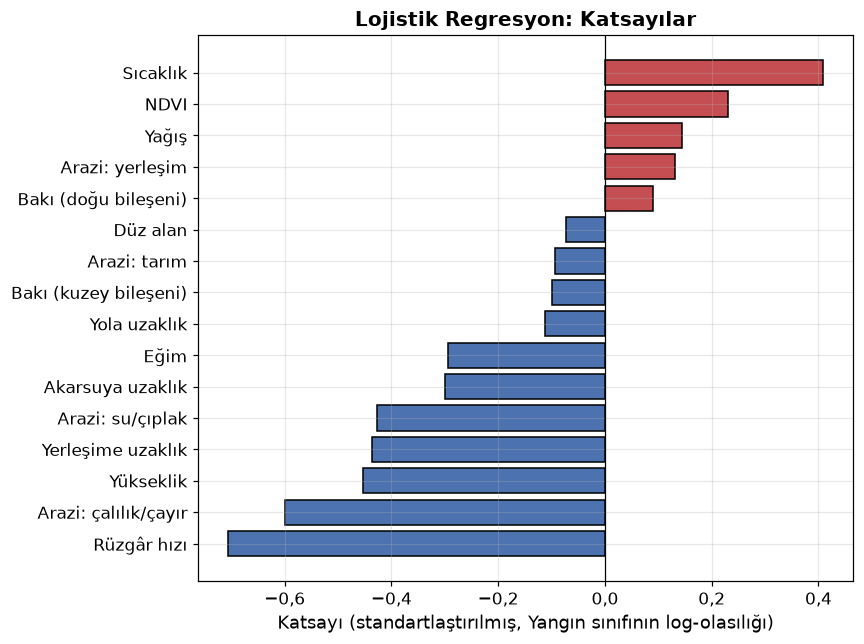

Ruzgar_Hizi        -0.706
Arazi_Calilik      -0.600
Yukseklik          -0.453
Yerlesim_Uzaklik   -0.437
Arazi_Su_Ciplak    -0.426
Sicaklik            0.409
Akarsu_Uzaklik     -0.300
Egim               -0.293
NDVI                0.230
Yagis               0.144
Arazi_Yerlesim      0.130
Yol_Uzaklik        -0.112
Baki_Cos           -0.099
Arazi_Tarim        -0.093
Baki_Sin            0.090
Baki_Duz           -0.073

Yangın olasılığını en çok artıran üç özellik : ['Sicaklik', 'NDVI', 'Yagis']
Yangın olasılığını en çok azaltan üç özellik: ['Ruzgar_Hizi', 'Arazi_Calilik', 'Yukseklik']

Olasılık oranları (bir std. sapmalık artış başına):
Sicaklik            1.505
NDVI                1.258
Yagis               1.155
Arazi_Yerlesim      1.139
Baki_Sin            1.094
Baki_Duz            0.930
Arazi_Tarim         0.911
Baki_Cos            0.906
Yol_Uzaklik         0.894
Egim                0.746
Akarsu_Uzaklik      0.741
Arazi_Su_Ciplak     0.653
Yerlesim_Uzaklik    0.646
Yukseklik           0.6

In [5]:
# İkili sınıflandırmada scikit-learn tek bir katsayı vektörü öğrenir; bu vektör
# clf.classes_ içindeki İKİNCİ sınıfın log-olasılığına aittir.
isaret = 1.0 if clf.classes_[1] == o.POZITIF else -1.0
katsayi = pd.Series(isaret * clf.coef_[0], index=o.OZELLIKLER)
s = katsayi.rename(index=o.OKUNUR).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(s.index, s.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in s.values], edgecolor="k")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Katsayı (standartlaştırılmış, Yangın sınıfının log-olasılığı)")
ax.set_title("Lojistik Regresyon: Katsayılar")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "lojistik_katsayi.png"), bbox_inches="tight")
plt.show()

print(katsayi.sort_values(key=np.abs, ascending=False).round(3).to_string())
print()
print("Yangın olasılığını en çok artıran üç özellik :", list(katsayi.sort_values().index[::-1][:3]))
print("Yangın olasılığını en çok azaltan üç özellik:", list(katsayi.sort_values().index[:3]))
oran = np.exp(katsayi)
print()
print("Olasılık oranları (bir std. sapmalık artış başına):")
print(oran.sort_values(ascending=False).round(3).to_string())

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [6]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    c_tahmin = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(float("nan"))  # bu algoritma regresyon yapmaz
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +nan · F1-makro 0.6989
  kat 2: eğitim  4170 · sınama   958 · R² +nan · F1-makro 0.6511
  kat 3: eğitim  4114 · sınama  1014 · R² +nan · F1-makro 0.7058
  kat 4: eğitim  4055 · sınama  1073 · R² +nan · F1-makro 0.7476
  kat 5: eğitim  4150 · sınama   978 · R² +nan · F1-makro 0.6098
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +nan ± nan
  F1-makro: 0.6826 ± 0.0476


C:\Users\BALTRON\AppData\Local\Temp\ipykernel_5716\299697540.py:16: RuntimeWarning: Mean of empty slice
  print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [7]:
o.sonuc_kaydet("lojistik_regresyon", None, cls,
               ek={"cv": cv_ozet, "tahmin": [str(v) for v in yp], "auc": auc,
                   "katsayi": katsayi.round(5).to_dict(),
                   "olasilik_orani": oran.round(5).to_dict()})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\lojistik_regresyon.json


{'algoritma': 'lojistik_regresyon',
 'regresyon': None,
 'siniflandirma': {'Accuracy': 0.734789391575663,
  'BalancedAcc': 0.7350762166544529,
  'F1_macro': 0.734788746105919,
  'F1_weighted': 0.7347810004689908},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [None, None, None, None, None],
   'F1_macro': [0.6989360924489809,
    0.6510653797122564,
    0.7057688688123471,
    0.7475531714662149,
    0.6097752496959599],
   'R2_ort': None,
   'R2_std': None,
   'F1_ort': 0.6826197524271518,
   'F1_std': 0.04758246203132198},
  'tahmin': ['Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',